### 1. Imports và configuration

In [1]:
from pathlib import Path
from dataclasses import dataclass
import hashlib
import sys
import warnings
import pandas as pd

import numpy as np
import torch
import torchtuples as tt
import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter
from pycox.models import LogisticHazard

# ============================================================
# Project setup
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name in {"notebooks", "scripts"}:
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

FIGURE_DIR = PROJECT_ROOT / "figures"
RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

from examples.data.longi_simulation import longi_sim
from examples.learner.coxsig import CoxSignature
from examples.learner.dynamic_deephit_ext import construct_df, Dynamic_DeepHit_ext
from examples.learner.DySurv.model_utils import DySurv, Loss
from examples.learner.dysurv_ext import DySurvWrapper, make_dysurv_input, add_duration_channel
from examples.learner.utils import score

# ============================================================
# Experiment configuration
# ============================================================

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set(style="whitegrid", font="STIXGeneral", context="talk", palette="colorblind")

n_samples = 1000
n_sampling_times = 200
n_longi_feats = 5
n_static_feats = 3
train_ratio = 0.8
val_ratio = 0.1
n_eval_times = 3

coefs = torch.tensor([1., 0., 1., 0., 5., 0.])
coef_mask = torch.ones_like(coefs)
simulation_feat_mask = torch.tensor([0, 1, 0, 0, 0])
theta = torch.tensor([0., -0.3, 0., 0.2, 0.])
hurst_list = [0.9, 0.45, 0.85, 0.35, 0.8]

# ---------- DySurv training ----------
FORCE_RETRAIN_DYSURV = False
DYSURV_NUM_DURATIONS = 60
DYSURV_LATENT_DIM = 20
DYSURV_BATCH_SIZE = 64
DYSURV_EPOCHS = 200
DYSURV_PATIENCE = 20
DYSURV_LR = 1e-3

/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### 2. Simulation và train/test split

In [2]:
# ---------- Generate survival data ----------
paths, surv_labels, static_feature, factor, ddh_info_sup, traj, org_paths = (
    longi_sim.Simulation().load(
        n_samples=n_samples,
        n_sampling_times=n_sampling_times,
        end_time=10,
        dim=n_longi_feats + 1,
        intercept=True,
        threshold=12,
        coefs=coefs,
        coefs_mask=coef_mask,
        important_feat_mask=simulation_feat_mask,
        hurst_list=hurst_list,
        theta=theta,
        n_static_feats=n_static_feats,
        save_path=str(FIGURE_DIR / "simu_data.pdf"),
        show=False,
    )
)

paths_init = paths.clone()

paths_np = np.asarray(paths, dtype=np.float32)
labels_np = np.asarray(surv_labels, dtype=np.float32)
static_np = None if static_feature is None else np.asarray(static_feature, dtype=np.float32)

sampling_times = paths_np[0, :, 0]
longi_feat_list = [f"X{i+1}" for i in range(n_longi_feats)]
coef_importance_mask = (coefs != 0).int()

# ---------- Shared train/test split ----------
indices = np.random.permutation(n_samples)
n_train = int(train_ratio * n_samples)

train_idx = indices[:n_train]
test_idx = indices[n_train:]

n_fit = int((1 - val_ratio) * len(train_idx))
fit_idx, val_idx = train_idx[:n_fit], train_idx[n_fit:]

def subset(x, idx):
    return None if x is None else x[idx]

paths_train, paths_test = paths[train_idx], paths[test_idx]
labels_train, labels_test = surv_labels[train_idx], surv_labels[test_idx]

static_train = subset(static_feature, train_idx)
static_test = subset(static_feature, test_idx)

# ---------- Shared prediction horizons ----------
tte = labels_np[labels_np[:, 1] == 1, 0]
quantile_levels = np.array([0.5, 0.75])
pred_times = np.quantile(np.array(tte), quantile_levels)

eval_times = np.array([
    max(np.quantile(tte, quantile_levels + (k + 1) * 0.05) - pred_times)
    for k in range(n_eval_times)
])

### 3. Train and evaluate CoxSig

In [3]:
# ---------- Train CoxSig ----------
coxsig = CoxSignature(sig_level=2, alphas=0.3, max_iter=200,)
coxsig.train(paths_train, labels_train, static_train, plot_loss=False,)

# ---------- Evaluate CoxSig ----------
coxsig_cindex = coxsig.score(paths_test, labels_test, pred_times, eval_times, "c_index", static_feat=static_test,)
coxsig_bs = coxsig.score(paths_test, labels_test, pred_times, eval_times, "bs", static_feat=static_test,)

### 4. Train and evaluate Dynamic DeepHit

In [4]:
# ---------- Prepare Dynamic DeepHit data ----------
cont_feat, bin_feat, time_scale, bin_df = ddh_info_sup

df = construct_df(
    paths.clone(), surv_labels,
    cont_feat, bin_feat, time_scale, bin_df,
)

ddh = Dynamic_DeepHit_ext()
(data, times, events), (mask1, mask2, mask3), data_mi = (
    ddh.preprocess(df, cont_feat, bin_feat)
)

ddh.sampling_times = sampling_times.copy()
ddh.ddh_info_sup = ddh_info_sup

train_data = (
    data[train_idx],
    data_mi[train_idx],
    events[train_idx],
    times[train_idx],
    mask1[train_idx],
    mask2[train_idx],
    mask3[train_idx],
)

# ---------- Train Dynamic DeepHit ----------
ddh.train(
    train_data,
    is_trained=True,
    plot_loss=False,
    ckpt_dir=str(RESULT_DIR / "dynamic_deephit_ckpt" / "simulation"),
)

# ---------- Predict survival ----------
pred_time_scale = (pred_times * time_scale).astype(int)
eval_time_scale = (eval_times * time_scale).astype(int)

ddh_surv_preds = ddh.predict(
    data[test_idx],
    data_mi[test_idx],
    pred_time_scale,
    eval_time_scale,
)

# ---------- Evaluate Dynamic DeepHit ----------
def evaluate_ddh(predictions, labels, pred_times, eval_times):
    cindex = np.full((len(pred_times), len(eval_times)), np.nan)
    brier = np.full_like(cindex, np.nan)

    labels = np.asarray(labels)

    for j, pred_time in enumerate(pred_times):
        eligible = labels[:, 0] >= pred_time

        y = labels[eligible].copy()
        y[:, 0] -= pred_time

        pred = predictions[:, j][eligible]

        cindex[j] = score("c_index", y, y, pred, eval_times)
        brier[j] = score("bs", y, y, pred, eval_times)

    return cindex, brier


ddh_cindex, ddh_bs = evaluate_ddh(
    ddh_surv_preds,
    labels_np[test_idx],
    pred_times,
    eval_times,
)

### 5. Train and evaluate DySurv

In [5]:
# ============================================================
# Prepare DySurv training and validation data
# ============================================================

x_fit = make_dysurv_input(paths_np[fit_idx], subset(static_np, fit_idx))
x_val = make_dysurv_input(paths_np[val_idx], subset(static_np, val_idx))

labtrans = LogisticHazard.label_transform(DYSURV_NUM_DURATIONS)
y_fit = labtrans.fit_transform(labels_np[fit_idx, 0], labels_np[fit_idx, 1].astype(int))
y_val = labtrans.transform(labels_np[val_idx, 0], labels_np[val_idx, 1].astype(int))

train_input = add_duration_channel(x_fit, y_fit)
val_input = add_duration_channel(x_val, y_val)
train = tt.tuplefy(train_input, (y_fit, train_input))
val = tt.tuplefy(val_input, (y_val, val_input))

# ============================================================
# Initialize DySurv
# ============================================================

net = DySurv(
    in_features=x_fit.shape[2],
    encoded_features=DYSURV_LATENT_DIM,
    out_features=labtrans.out_features,
    seq_len=x_fit.shape[1],
)

dysurv_model = LogisticHazard(
    net,
    tt.optim.Adam(DYSURV_LR),
    duration_index=labtrans.cuts,
    loss=Loss([1.0, 0.1, 0.01]),
)

# ============================================================
# Load or train DySurv checkpoint
# ============================================================

def array_digest(*arrays):
    digest = hashlib.sha256()
    for array in arrays:
        if array is None:
            digest.update(b"none")
            continue
        array = np.ascontiguousarray(np.asarray(array))
        digest.update(str((array.shape, array.dtype)).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()

checkpoint_path = RESULT_DIR / "dysurv_ckpt" / "simulation" / "model.pt"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

checkpoint_config = {
    "num_durations": DYSURV_NUM_DURATIONS,
    "latent_dim": DYSURV_LATENT_DIM,
    "input_shape": tuple(x_fit.shape[1:]),
    "data_digest": array_digest(paths_np, labels_np, static_np, fit_idx, val_idx, train_idx, test_idx),
}

if checkpoint_path.is_file() and not FORCE_RETRAIN_DYSURV:
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    if checkpoint.get("config") != checkpoint_config:
        raise ValueError("DySurv checkpoint does not match this simulation. Set FORCE_RETRAIN_DYSURV=True.")
    if not np.allclose(checkpoint["duration_index"], labtrans.cuts):
        raise ValueError("DySurv checkpoint duration cuts mismatch.")
    dysurv_model.net.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded DySurv: {checkpoint_path}")
else:
    dysurv_log = dysurv_model.fit(
        *train,
        batch_size=DYSURV_BATCH_SIZE,
        epochs=DYSURV_EPOCHS,
        val_data=val,
        callbacks=[tt.cb.EarlyStopping(patience=DYSURV_PATIENCE)],
        verbose=False,
    )
    torch.save({
        "model_state_dict": dysurv_model.net.state_dict(),
        "duration_index": np.asarray(labtrans.cuts),
        "config": checkpoint_config,
    }, checkpoint_path)
    print(f"Saved DySurv: {checkpoint_path}")

dysurv_model.net.eval()
dysurv = DySurvWrapper(dysurv_model)

# ============================================================
# Evaluate DySurv
# ============================================================

censor_km = KaplanMeierFitter()
censor_km.fit(
    durations=labels_np[train_idx, 0],
    event_observed=1 - labels_np[train_idx, 1].astype(int),
)

x_test = paths_np[test_idx]
y_test = labels_np[test_idx]
static_test_np = subset(static_np, test_idx)

shape = (len(pred_times), len(eval_times))
dysurv_cindex = np.full(shape, np.nan)
dysurv_bs = np.full(shape, np.nan)

for prediction_idx, prediction_time in enumerate(pred_times):
    dysurv_cindex[prediction_idx] = dysurv.score(
        x_test, y_test, prediction_time, eval_times,
        metric="c_index", static_feat=static_test_np,
    )
    dysurv_bs[prediction_idx] = dysurv.score(
        x_test, y_test, prediction_time, eval_times,
        metric="bs", static_feat=static_test_np, censor_km=censor_km,
    )

Loaded DySurv: /Users/vantnguy/Working/survinsights/results/dysurv_ckpt/simulation/model.pt


### 6. Comparison và visualization

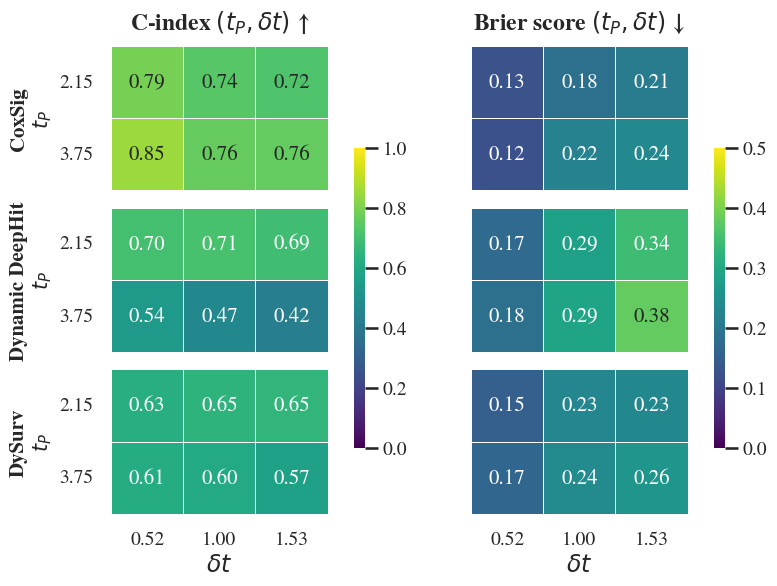

In [6]:
# ============================================================
# Compact performance heatmaps
# ============================================================

models = ["CoxSig", "Dynamic DeepHit", "DySurv"]
cindex_results = [coxsig_cindex, ddh_cindex, dysurv_cindex]
bs_results = [coxsig_bs, ddh_bs, dysurv_bs]

fig, axs = plt.subplots(3, 2, figsize=(9, 6))
plt.subplots_adjust(
    left=0.16, right=0.88, bottom=0.12, top=0.90,
    hspace=0.12, wspace=0.25,
)

# ---------- Shared colorbars ----------
cbar_ax_1 = fig.add_axes([0.47, 0.23, 0.012, 0.50])
cbar_ax_2 = fig.add_axes([0.87, 0.23, 0.012, 0.50])

# ---------- Heatmaps ----------
for i, model in enumerate(models):
    for j, (values, vmin, vmax, cbar_ax) in enumerate([
        (cindex_results[i], 0, 1, cbar_ax_1),
        (bs_results[i], 0, 0.5, cbar_ax_2),
    ]):
        ax = axs[i, j]

        sns.heatmap(
            values,
            annot=True,
            fmt=".2f",
            annot_kws={"size": 15},
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            square=True,
            linewidths=0.5,
            linecolor="white",
            ax=ax,
            cbar=(i == 2),
            cbar_ax=cbar_ax if i == 2 else None,
        )

        # ---------- Shared x-axis labels ----------
        if i == 2:
            ax.set_xticklabels(
                [f"{x:.2f}" for x in eval_times],
                rotation=0, fontsize=14,
            )
            ax.set_xlabel(r"$\delta t$", fontsize=17, fontweight="semibold")
        else:
            ax.set_xticks([])

        # ---------- Shared y-axis labels ----------
        if j == 0:
            ax.set_yticklabels(
                [f"{x:.2f}" for x in pred_times],
                rotation=0,
                fontsize=14,
            )
            ax.set_ylabel(
                f"{model}\n$t_P$",
                fontsize=15,
                fontweight="semibold",
            )
        else:
            ax.set_yticks([])
            ax.set_ylabel("")

        if i == 0:
            ax.set_title(
                r"C-index $(t_P,\delta t)$ ↑" if j == 0
                else r"Brier score $(t_P,\delta t)$ ↓",
                fontsize=17,
                fontweight="semibold",
                pad=12,
            )

# ---------- Colorbar formatting ----------
for cbar_ax in [cbar_ax_1, cbar_ax_2]:
    cbar_ax.tick_params(labelsize=14)

# ---------- Save figure ----------
fig.savefig(
    FIGURE_DIR / "simu_perf_comparison.pdf",
    bbox_inches="tight",
    dpi=300,
)
plt.show()

### 7. Explanation utilities

In [7]:
# ============================================================
# Shared explanation and plotting utilities
# ============================================================

from functools import partial
from explanation_plot_utils import (
    DEFAULT_COLORS,
    load_explanations as _load_explanations,
    importance_summary as _importance_summary,
    explanation_array,
    plot_global as _plot_global,
    plot_temporal as _plot_temporal,
    style_axis,
)

COLORS = DEFAULT_COLORS
FEATURE_LABELS = ([rf"$X_{{{i+1}}}$" for i in range(n_longi_feats)]
                  + [rf"$W_{{{i+1}}}$" for i in range(n_static_feats)])
MODEL_LABELS = {"CoxSig": "CoxSig explanation", "DDH": "DDH explanation", "DySurv": "DySurv explanation"}

plot_global = partial(_plot_global, labels=FEATURE_LABELS, colors=COLORS)
plot_temporal = partial(_plot_temporal, sampling_times=sampling_times,
                        n_longi_feats=n_longi_feats, labels=FEATURE_LABELS, colors=COLORS)

explanations = {}
def load_explanations(explanation_kind="mean"):
    if explanation_kind not in explanations:
        explanations[explanation_kind] = _load_explanations(
            RESULT_DIR, "simu", kind=explanation_kind, models=tuple(MODEL_LABELS)
        )
    return explanations[explanation_kind]

def importance_summary(results, method_idx):
    return _importance_summary(results, method_idx, temporal_ci_mode="valid")

# ============================================================
# Simulation-specific theoretical importance
# ============================================================

def change_intervals(values, rtol=1e-4, atol=1e-8):
    values = np.asarray(values, dtype=float)
    finite = np.flatnonzero(np.isfinite(values))
    if not len(finite):
        raise ValueError("No finite temporal importance")
    values = values[:finite[-1] + 1]
    changes = np.flatnonzero(~np.isclose(values[1:], values[:-1], rtol=rtol,
                                         atol=atol, equal_nan=True)) + 1
    return [0, *changes.tolist(), len(values)]

def prediction_horizon(prediction_idx):
    prediction_time = float(pred_times[prediction_idx])
    horizon_idx = int(np.searchsorted(sampling_times, prediction_time, side="right"))
    if horizon_idx < 1:
        raise ValueError("Prediction time precedes the first sampling time")
    return prediction_time, horizon_idx

def theoretical_temporal(prediction_time, horizon_idx, intervals):
    selected = [factor.T[i][:, horizon_idx - 1:horizon_idx]
                for i in range(len(surv_labels)) if surv_labels[i, 0] > prediction_time]
    if not selected:
        raise ValueError("No individuals at risk at prediction time")
    theoretical = np.nanmean(np.asarray(selected).T, axis=1).mean(axis=-1).copy()
    n_time = min(horizon_idx, theoretical.shape[1])
    cuts = np.unique(np.clip([0, *intervals, n_time], 0, n_time)).astype(int)
    for left, right in zip(cuts[:-1], cuts[1:]):
        if right > left:
            segment = theoretical[:, left:right]
            count = np.isfinite(segment).sum(axis=1, keepdims=True)
            theoretical[:, left:right] = np.divide(
                np.nansum(segment, axis=1, keepdims=True), count,
                out=np.full((len(segment), 1), np.nan), where=count > 0)
    theoretical[theoretical == 0] = 1e-6
    return theoretical


### 8. Main model comparisons — global and interval-wise importance

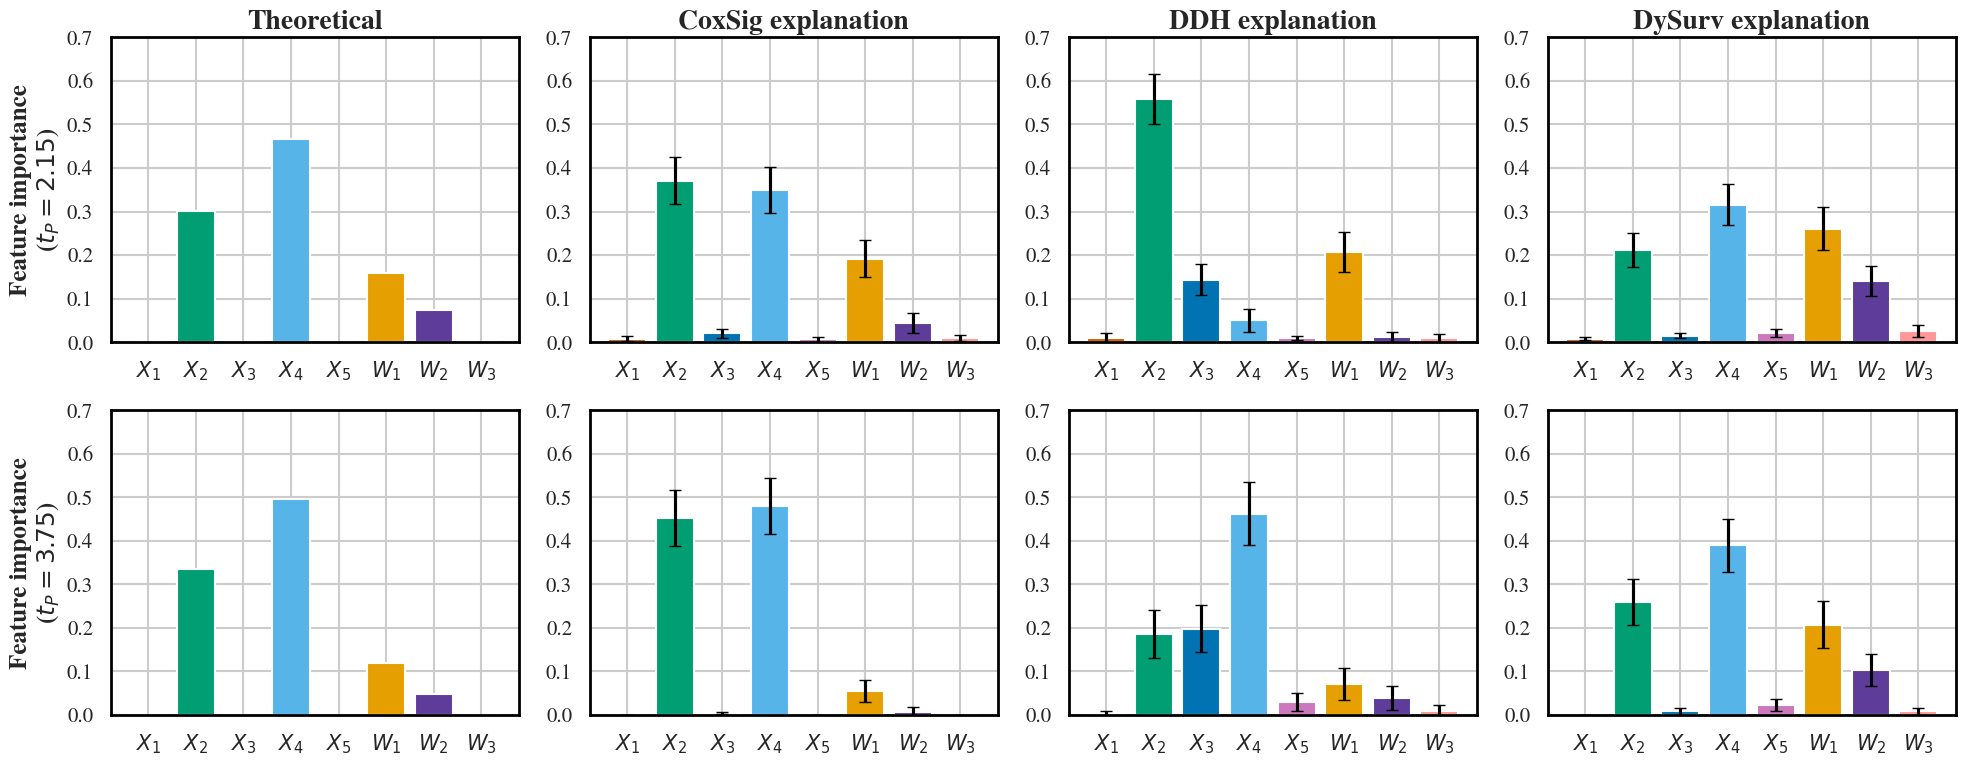

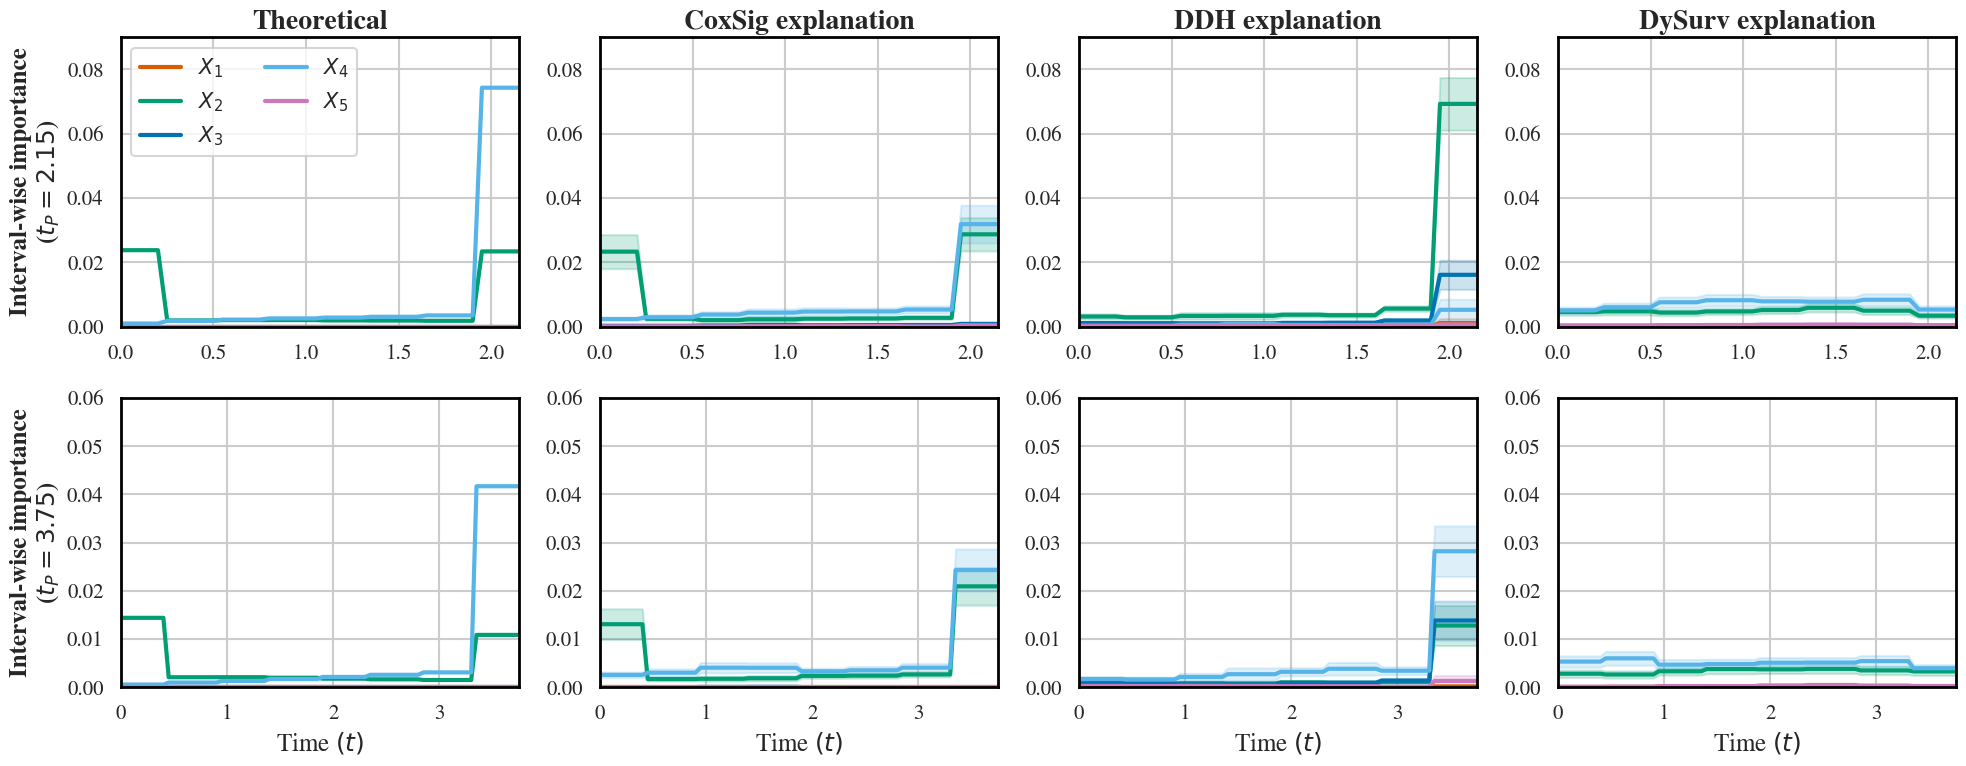

In [8]:
def compare_models(explanation_kind="mean", view="global", y_limits=None):
    results = load_explanations(explanation_kind)
    fig, axes = plt.subplots(len(pred_times), 4, figsize=(20, 4 * len(pred_times)), squeeze=False)
    titles = ["Theoretical", *MODEL_LABELS.values()]
    for prediction_idx in range(len(pred_times)):
        prediction_time, horizon_idx = prediction_horizon(prediction_idx)
        summaries = {model: importance_summary(result, prediction_idx)
                     for model, result in results.items()}
        intervals = change_intervals(summaries["CoxSig"].temporal_mean[1])
        reference = theoretical_temporal(prediction_time, horizon_idx, intervals)
        limit = None if y_limits is None else y_limits[prediction_idx]
        for col, ax in enumerate(axes[prediction_idx]):
            if col == 0:
                if view == "global":
                    plot_global(ax, np.nansum(reference[:, :horizon_idx], axis=1))
                else:
                    plot_temporal(ax, reference, horizon_idx=horizon_idx)
            else:
                summary = summaries[list(MODEL_LABELS)[col - 1]]
                if view == "global":
                    plot_global(ax, summary.global_mean, summary.global_ci)
                else:
                    plot_temporal(ax, summary.temporal_mean, summary.temporal_ci, horizon_idx=horizon_idx)
            style_axis(ax, titles[col] if prediction_idx == 0 else None, None if limit is None else (0, limit))
            if view == "temporal":
                ax.set_xlim(sampling_times[0], sampling_times[horizon_idx - 1])
                if prediction_idx == len(pred_times) - 1:
                    ax.set_xlabel(r"Time $(t)$")
        axes[prediction_idx, 0].set_ylabel(
            ("Feature" if view == "global" else "Interval-wise")
            + f" importance\n($t_P={prediction_time:.2f}$)", fontweight="semibold")
    if view == "temporal":
        axes[0, 0].legend(ncols=2, fontsize=15)
    fig.tight_layout()
    filename = f"shap_simu_{explanation_kind}_score_per_{'feat' if view == 'global' else 'longi'}.pdf"
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()

compare_models("mean", "global", y_limits=[0.7] * len(pred_times))
compare_models("mean", "temporal", y_limits=[0.09, 0.06])

### 9. Single prediction-time comparison

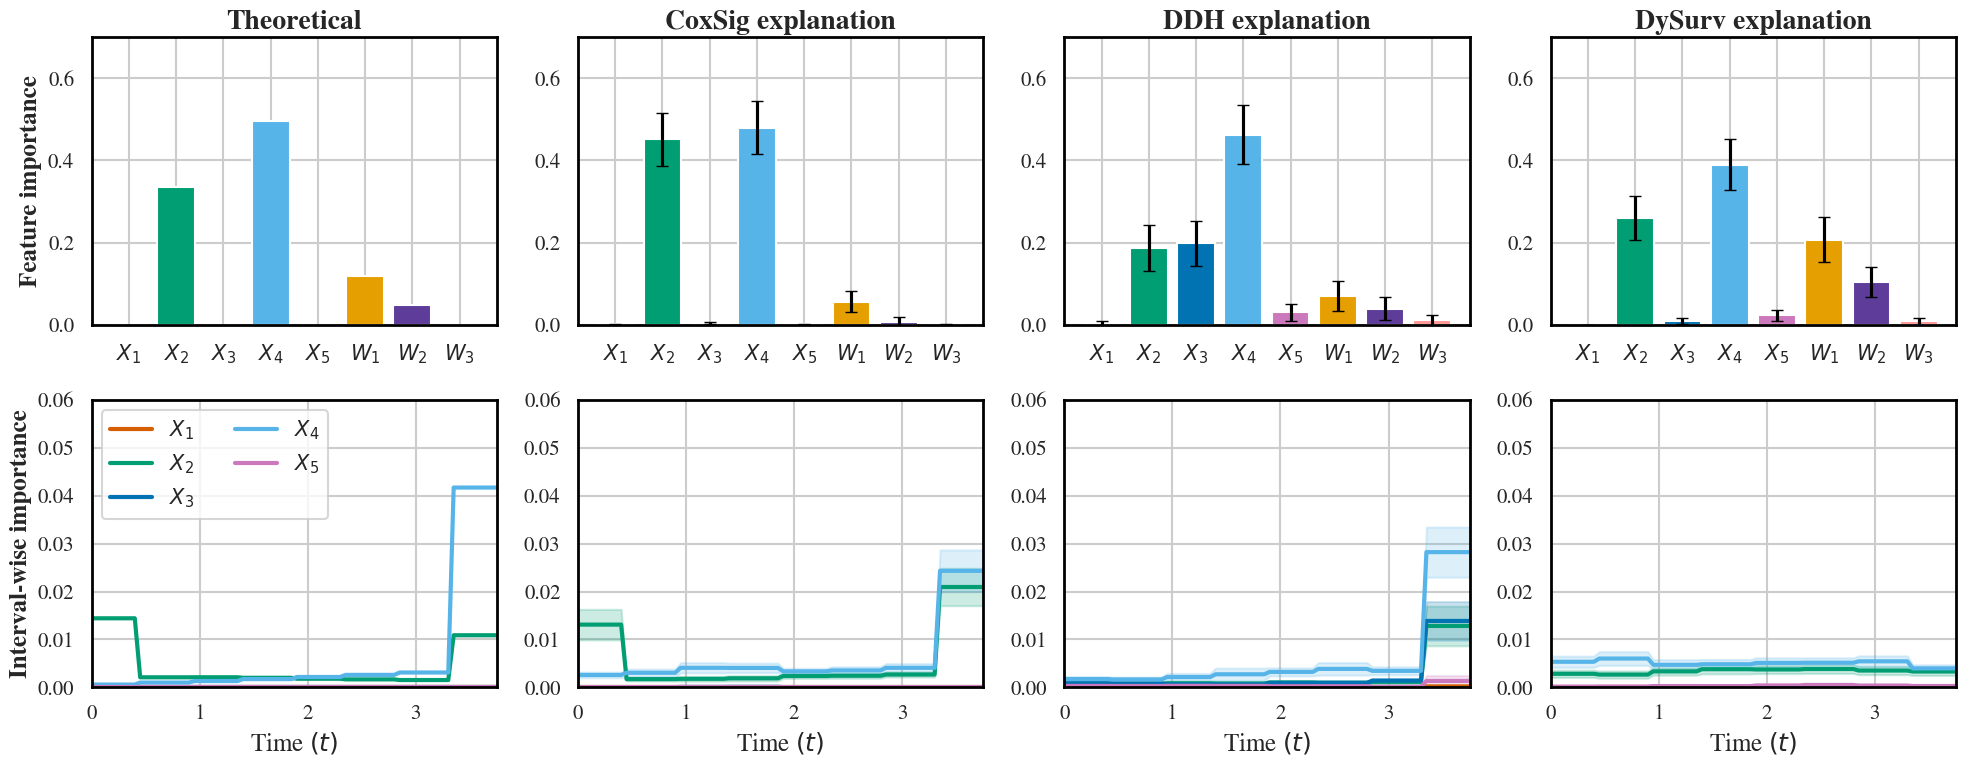

In [9]:
prediction_idx = 1
explanation_kind = "mean"
ylims = [(0, 0.7), (0, 0.06)]

model_results = load_explanations(explanation_kind)
prediction_time, horizon_idx = prediction_horizon(prediction_idx)

summaries = {
    model: importance_summary(result, prediction_idx)
    for model, result in model_results.items()
}

intervals = change_intervals(summaries["CoxSig"].temporal_mean[1])
reference = theoretical_temporal(prediction_time, horizon_idx, intervals)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for col, model in enumerate([None, *MODEL_LABELS]):
    summary = None if model is None else summaries[model]
    title = "Theoretical" if model is None else MODEL_LABELS[model]

    global_values = (
        np.nansum(reference[:, :horizon_idx], axis=1)
        if summary is None else summary.global_mean
    )

    plot_global(axes[0, col], global_values, None if summary is None else summary.global_ci)
    plot_temporal(axes[1, col], reference if summary is None else summary.temporal_mean,
                  None if summary is None else summary.temporal_ci, horizon_idx=horizon_idx)

    for row in range(2):
        style_axis(axes[row, col], title if row == 0 else None)
        axes[row, col].set_ylim(*ylims[row])

    axes[1, col].set_xlim(sampling_times[0], sampling_times[horizon_idx - 1])
    axes[1, col].set_xlabel("Time $(t)$", fontsize=18)

axes[0, 0].set_ylabel("Feature importance", fontweight="semibold")
axes[1, 0].set_ylabel("Interval-wise importance", fontweight="semibold")
axes[1, 0].legend(ncols=2, fontsize=15)

fig.tight_layout()
fig.savefig(FIGURE_DIR / f"shap_simu_{explanation_kind}_score_1pt.pdf", bbox_inches="tight")
plt.show()

### 10. Threshold selection ($\delta_1$)

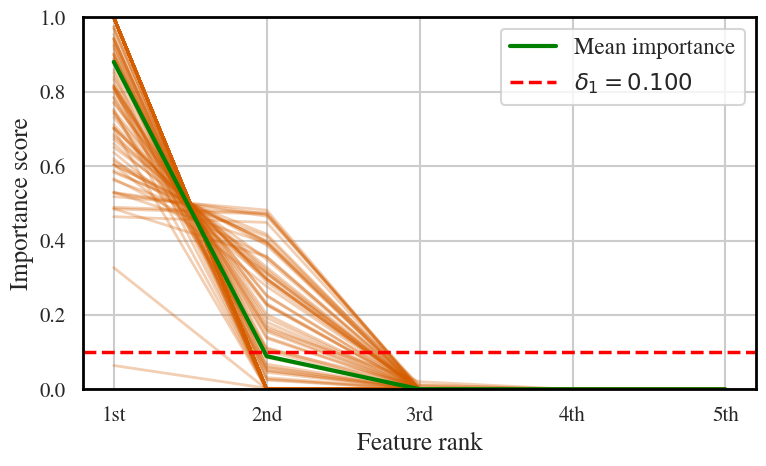

In [10]:
model_name = "CoxSig"
prediction_idx = 1
delta_1 = 0.1
values = importance_summary(load_explanations("med")[model_name], prediction_idx).individual_global
ranked = np.sort(values[:, :n_longi_feats], axis=1)[:, ::-1]
ranked = ranked[np.any(ranked != 0, axis=1)]
fig, ax = plt.subplots(figsize=(8, 5))
for row in ranked:
    ax.plot(np.arange(1, n_longi_feats + 1), row, color="r", alpha=0.3, lw=2)
ax.plot(np.arange(1, n_longi_feats + 1), ranked.mean(axis=0), color="green", lw=3, label="Mean importance")
ax.axhline(delta_1, color="red", ls="--", lw=2.5, label=rf"$\delta_1={delta_1:.3f}$")
ax.set(xlabel="Feature rank", ylabel="Importance score", ylim=(0, 1))
ax.set_xticks(np.arange(1, n_longi_feats + 1), ["1st", "2nd", "3rd", "4th", "5th"][:n_longi_feats])
ax.legend()
style_axis(ax)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"simu_{model_name}_delta1_selection.pdf", bbox_inches="tight")
plt.show()

### 11. Local individual explanations

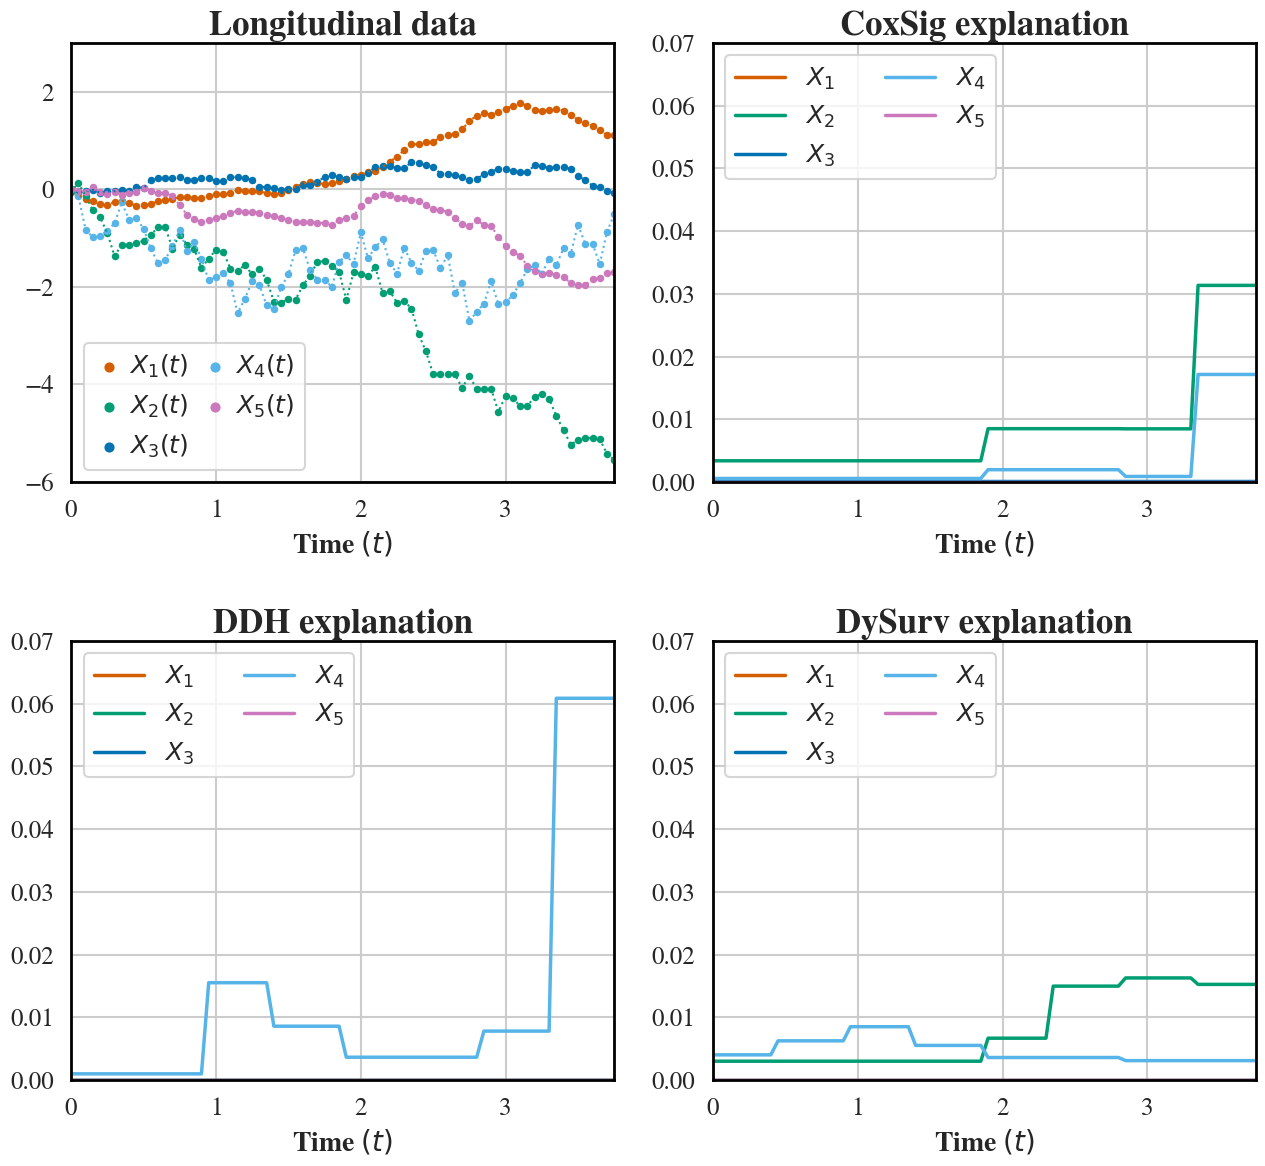

In [61]:
# ============================================================
# Configuration
# ============================================================

colors = ["r", "g", "b", "c", "m"]

sel_pred_time_id = 1
pred_time = float(pred_times[sel_pred_time_id])
individual_id = 64

shap_models = {
    "CoxSig": load_explanations("mean")["CoxSig"],
    "DDH": load_explanations("mean")["DDH"],
    "DySurv": load_explanations("mean")["DySurv"],
}

selected_indices = {
    "CoxSig": np.load(
        str(RESULT_DIR / "selected_explain_indices_CoxSig.npy"),
        allow_pickle=True,
    ),
    "DDH": np.load(
        str(RESULT_DIR / "selected_explain_indices_DDH.npy"),
        allow_pickle=True,
    ),
    "DySurv": np.load(
        str(RESULT_DIR / "selected_explain_indices_DySurv.npy"),
        allow_pickle=True,
    ),
}

# ============================================================
# Individual selection
# ============================================================

local_sampling_times = np.asarray(paths[individual_id, :, 0])
time_step = local_sampling_times[1] - local_sampling_times[0]

if surv_labels[individual_id, 0] <= pred_time + 0.5:
    raise ValueError(
        f"Individual {individual_id} is not eligible "
        f"at prediction time {pred_time:.2f}."
    )

# ---------- Find common explained individuals ----------
common_indices = None

for name in shap_models:
    indices = np.asarray(
        selected_indices[name][sel_pred_time_id],
        dtype=int,
    )

    if common_indices is None:
        common_indices = set(indices)
    else:
        common_indices &= set(indices)

if individual_id not in common_indices:
    available = sorted(common_indices)

    raise ValueError(
        f"Individual {individual_id} does not have explanations "
        f"for all three models.\n"
        f"Available common individuals: {available[:20]}"
    )

# ============================================================
# Figure: 2 x 2
# ============================================================

fig, axs = plt.subplots(2, 2, figsize=(13, 12))
axs = axs.flatten()

# ---------- Longitudinal observations ----------
mask = local_sampling_times <= pred_time

for l, ts in enumerate(paths[individual_id, :, 1:].T):
    axs[0].plot(
        local_sampling_times[mask],
        ts[mask],
        color=colors[l],
        linestyle="dotted",
        linewidth=1.5,
    )

    axs[0].scatter(
        local_sampling_times[mask],
        ts[mask],
        color=colors[l],
        s=15,
        label=rf"$X_{{{l+1}}}(t)$",
    )

axs[0].set_title(
    "Longitudinal data",
    fontsize=25,
    fontweight="semibold",
)

axs[0].set_ylim(-6, 3)

axs[0].legend(
    ncols=2,
    loc="lower left",
    handletextpad=0.2,
    columnspacing=0.5,
    handlelength=1.2,
    markerscale=1.5,
    fontsize=18,
)

# ============================================================
# Local SHAP explanations
# ============================================================

for col, (name, all_shap) in enumerate(
    shap_models.items(), start=1
):
    indices = np.asarray(
        selected_indices[name][sel_pred_time_id],
        dtype=int,
    )

    shap_idx = int(
        np.flatnonzero(indices == individual_id)[0]
    )

    result = all_shap[sel_pred_time_id][shap_idx]

    a = np.asarray(result[0], dtype=float)
    b = np.asarray(result[1], dtype=float)

    shap_value = np.divide(
        a,
        b,
        out=np.full_like(a, np.nan, dtype=float),
        where=b != 0,
    )

    # ---------- Plot longitudinal SHAP importance ----------
    for l in range(n_longi_feats):
        axs[col].plot(
            local_sampling_times,
            shap_value[l],
            linewidth=2.5,
            color=colors[l],
            label=rf"$X_{{{l+1}}}$",
        )

    axs[col].set_title(
        f"{name} explanation",
        fontsize=25,
        fontweight="semibold",
    )

    axs[col].legend(
        loc="upper left",
        ncols=2,
        fontsize=18,
    )
    axs[col].set_ylim(0, 0.07)

# ============================================================
# Figure formatting
# ============================================================

for ax in axs:
    for spine in ax.spines.values():
        spine.set_linewidth(2)
        spine.set_edgecolor("black")

    ax.set_xlabel(
        "Time $(t)$",
        fontsize=20,
        fontweight="bold",
    )

    ax.set_xlim(0, pred_time)
    ax.tick_params(axis="both", labelsize=18)

# fig.suptitle(
#     rf"Individual {individual_id} ($t_P={pred_time:.2f}$)",
#     fontsize=19,
#     fontweight="semibold",
# )

plt.tight_layout(h_pad=2.0, w_pad=1.5)

fig.savefig(
    FIGURE_DIR / "shap_simu_expl_local.pdf",
    bbox_inches="tight",
)

plt.show()

### 12. Median-target figures

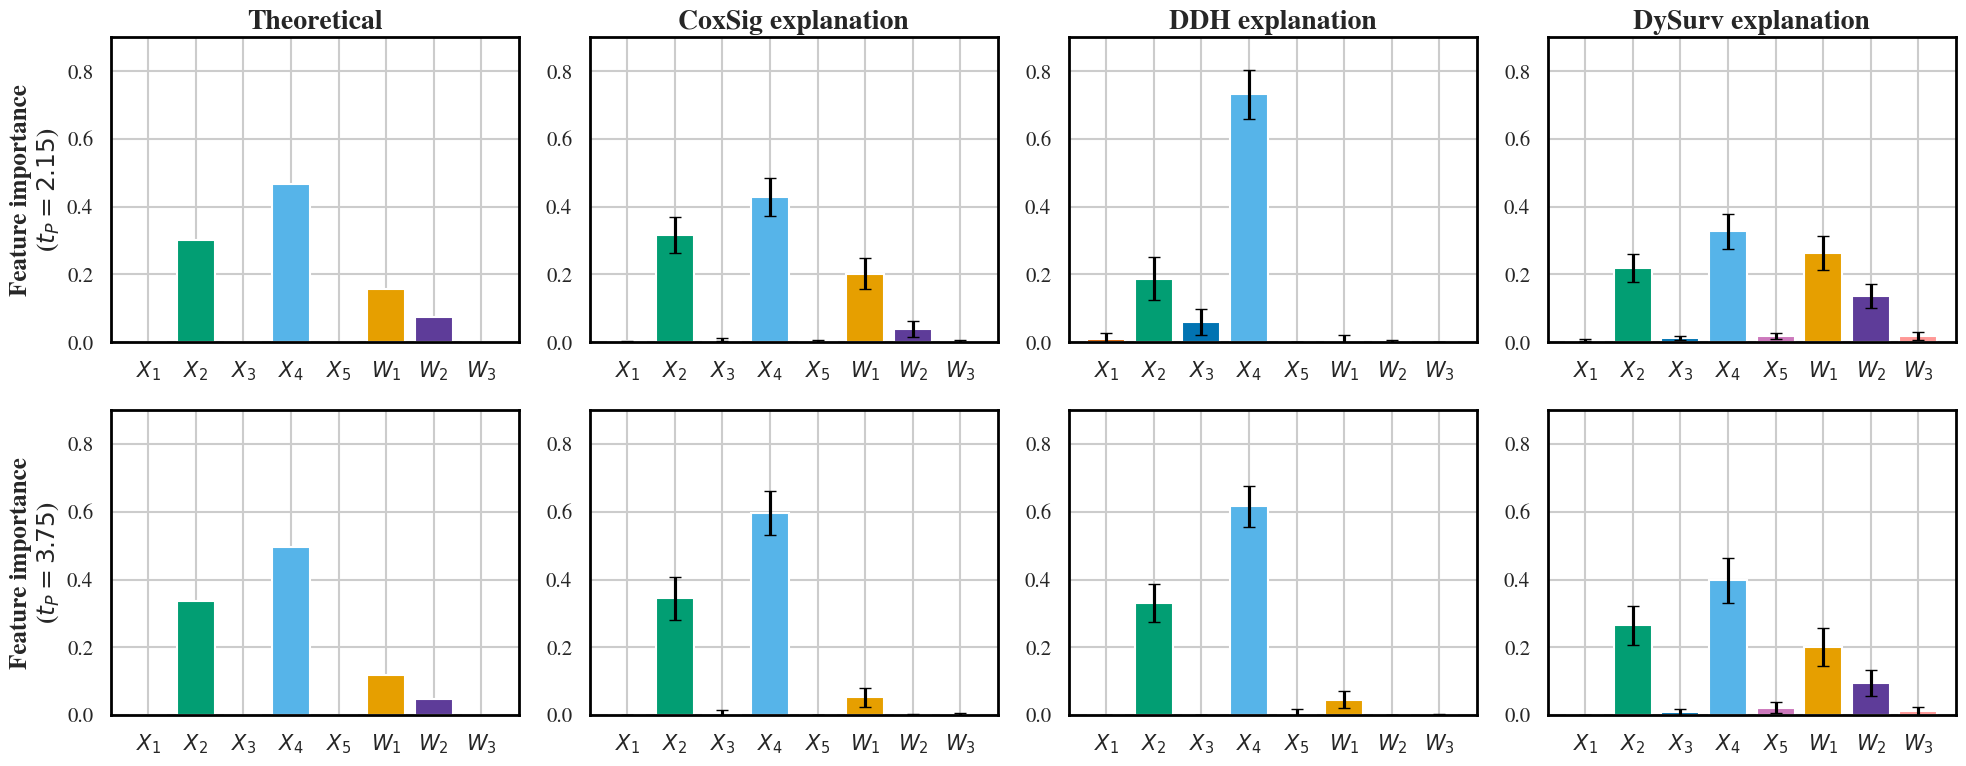

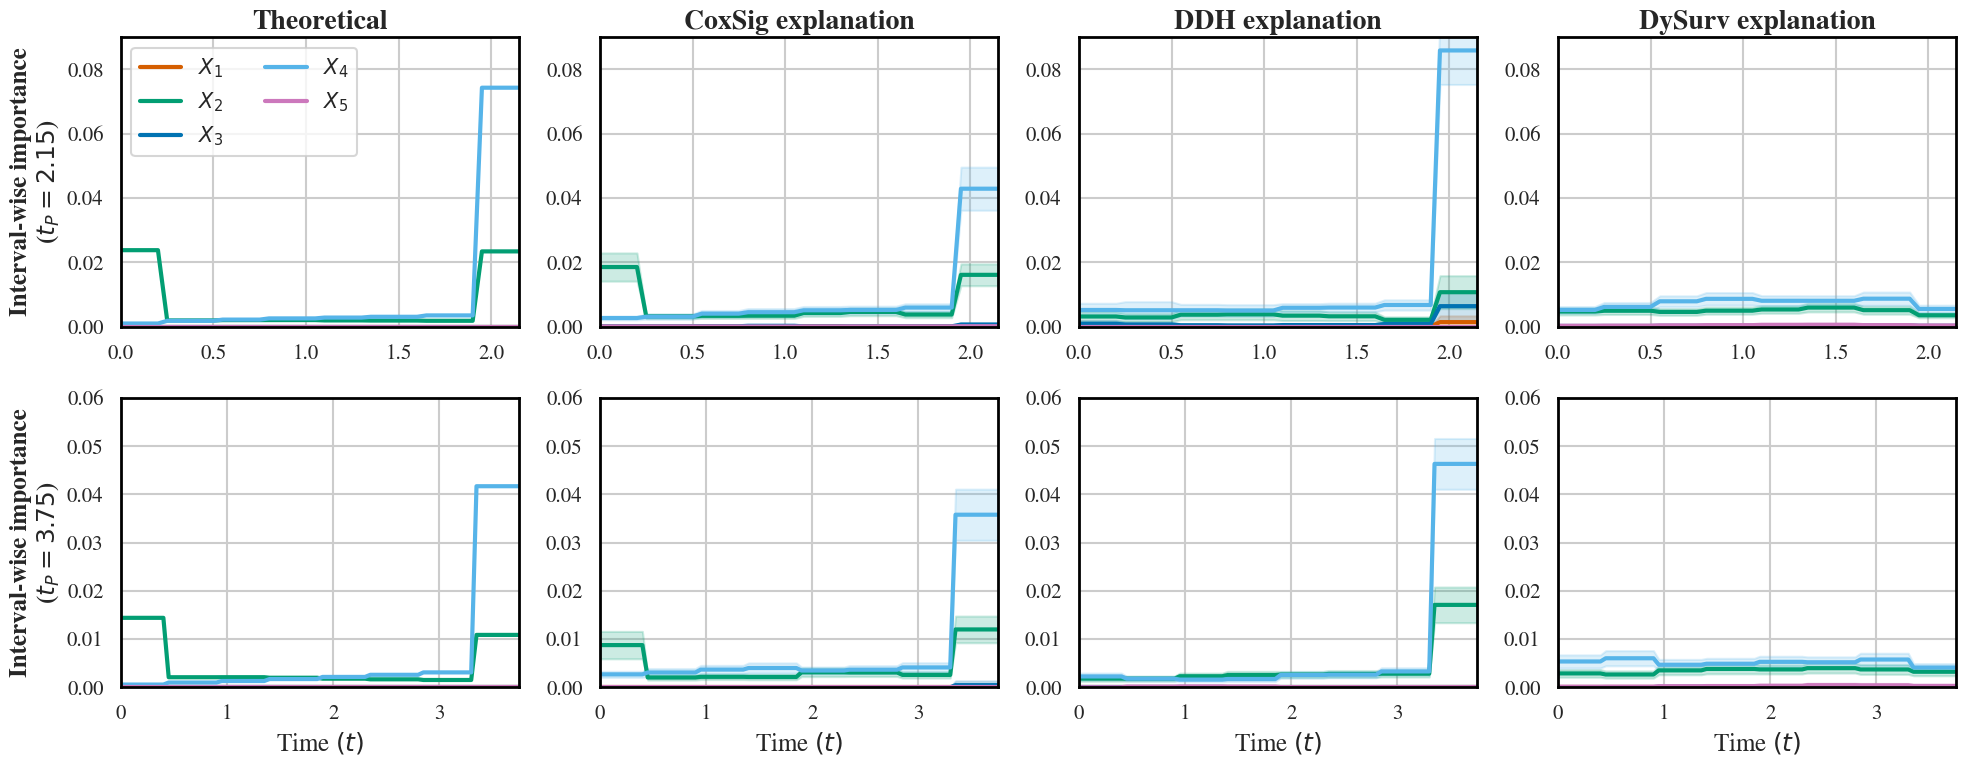

In [12]:
compare_models("med", "global", y_limits=[0.9] * len(pred_times))
compare_models("med", "temporal", y_limits=[0.09, 0.06])

### 13. CoxSig explainer comparison (DynSurvX / WindowSHAP / JointLIME)

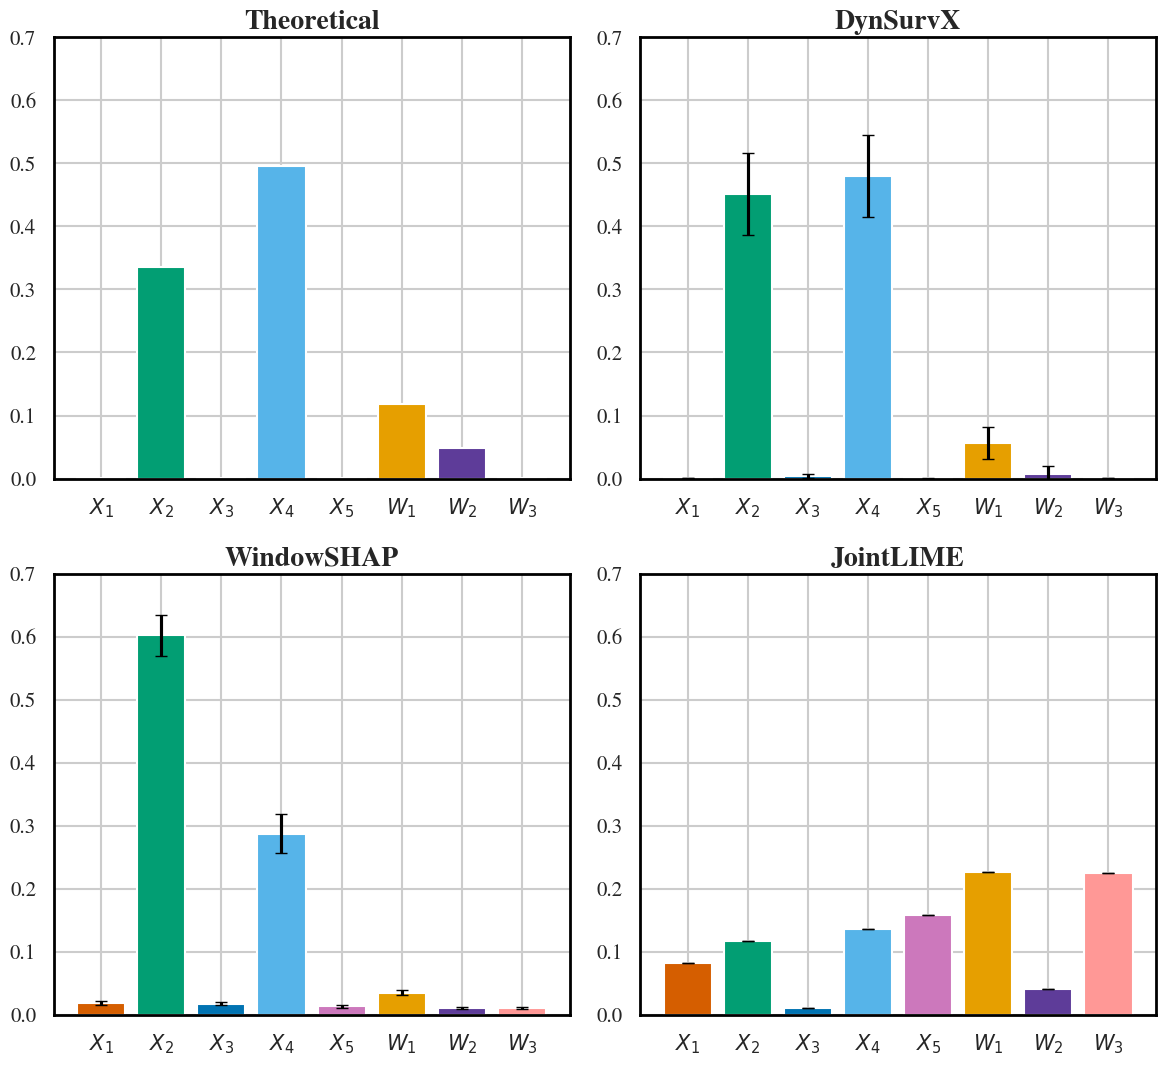

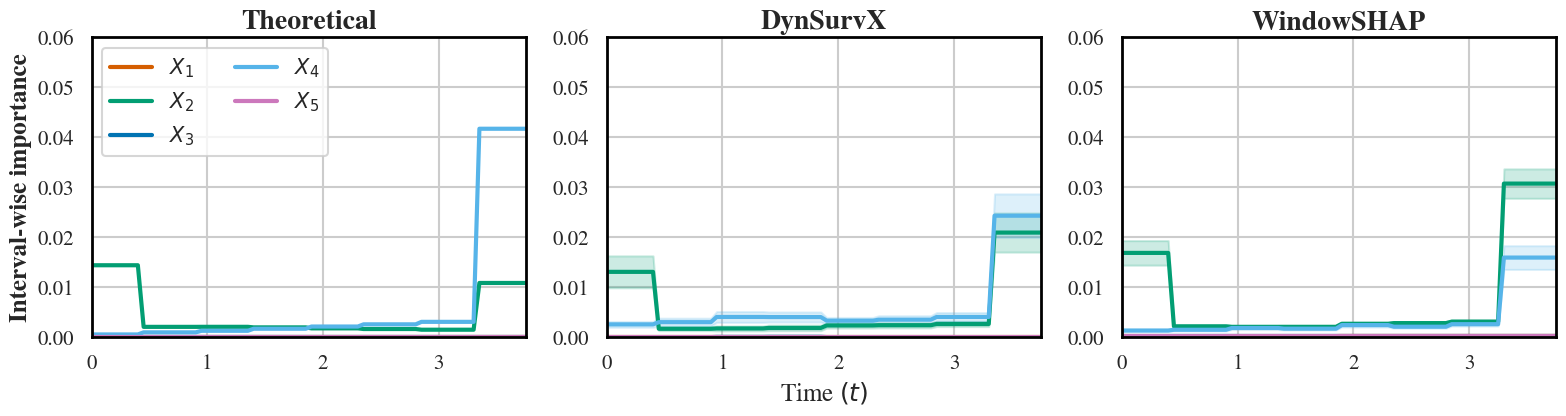

In [13]:
prediction_idx = 1
prediction_time, horizon_idx = prediction_horizon(prediction_idx)

comparison_results = {
    "DynSurvX": (load_explanations("mean")["CoxSig"], prediction_idx),
    "WindowSHAP": (np.load(RESULT_DIR / "shap_simu_mean_CoxSig_window_50.npy", allow_pickle=True), prediction_idx - 1),
    "JointLIME": (np.load(RESULT_DIR / "shap_simu_mean_CoxSig_jointlime.npy", allow_pickle=True), prediction_idx - 1),
}
comparison = {name: importance_summary(result, method_idx)
              for name, (result, method_idx) in comparison_results.items()}
intervals = change_intervals(comparison["DynSurvX"].temporal_mean[1])
reference = theoretical_temporal(prediction_time, horizon_idx, intervals)

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, (name, summary) in zip(axes.flat, [("Theoretical", None), *comparison.items()]):
    plot_global(ax, np.nansum(reference[:, :horizon_idx], axis=1) if summary is None else summary.global_mean,
                None if summary is None else summary.global_ci)
    style_axis(ax, name, (0, 0.7))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "shap_simu_mean_score_per_feat_compare.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, summary) in zip(axes, [("Theoretical", None), *list(comparison.items())[:2]]):
    plot_temporal(ax, reference if summary is None else summary.temporal_mean,
                  None if summary is None else summary.temporal_ci, horizon_idx=horizon_idx)
    style_axis(ax, name, (0, 0.06))
    ax.set_xlim(sampling_times[0], sampling_times[horizon_idx - 1])
axes[0].set_ylabel("Interval-wise importance", fontweight="semibold")
axes[1].set_xlabel(r"Time $(t)$")
axes[0].legend(ncols=2, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "shap_simu_mean_score_per_longi_compare.pdf", bbox_inches="tight")
plt.show()

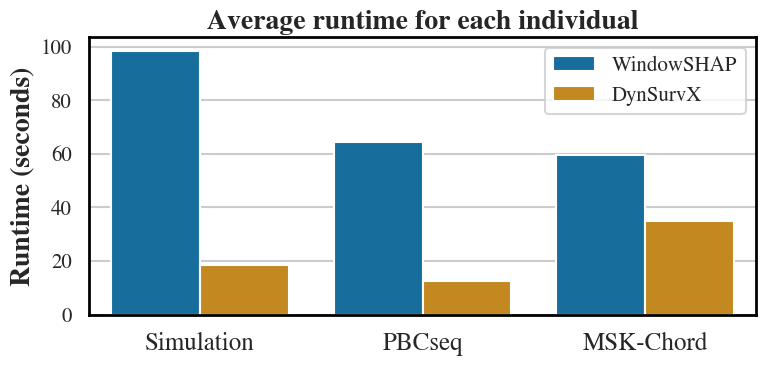

In [14]:
# ============================================================
# Runtime comparison
# ============================================================

runtime_df = pd.DataFrame([
    ["Simulation", "WindowSHAP", 98.6],
    ["Simulation", "DynSurvX", 18.7],
    ["PBCseq", "WindowSHAP", 64.4],
    ["PBCseq", "DynSurvX", 12.5],
    ["MSK-Chord", "WindowSHAP", 59.7],
    ["MSK-Chord", "DynSurvX", 35.1],
], columns=["Dataset", "Explainer", "Runtime (seconds)"])

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=runtime_df,
    x="Dataset",
    y="Runtime (seconds)",
    hue="Explainer",
    palette="colorblind",
    errorbar=None,
    ax=ax,
)

style_axis(ax, "Average runtime for each individual")
ax.set_xlabel("")
ax.set_ylabel("Runtime (seconds)", fontsize=20, fontweight="semibold")
ax.legend(fontsize=15, loc="upper right")
ax.tick_params(axis="x", labelsize=18)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "runtime_comparison.pdf", bbox_inches="tight")
plt.show()

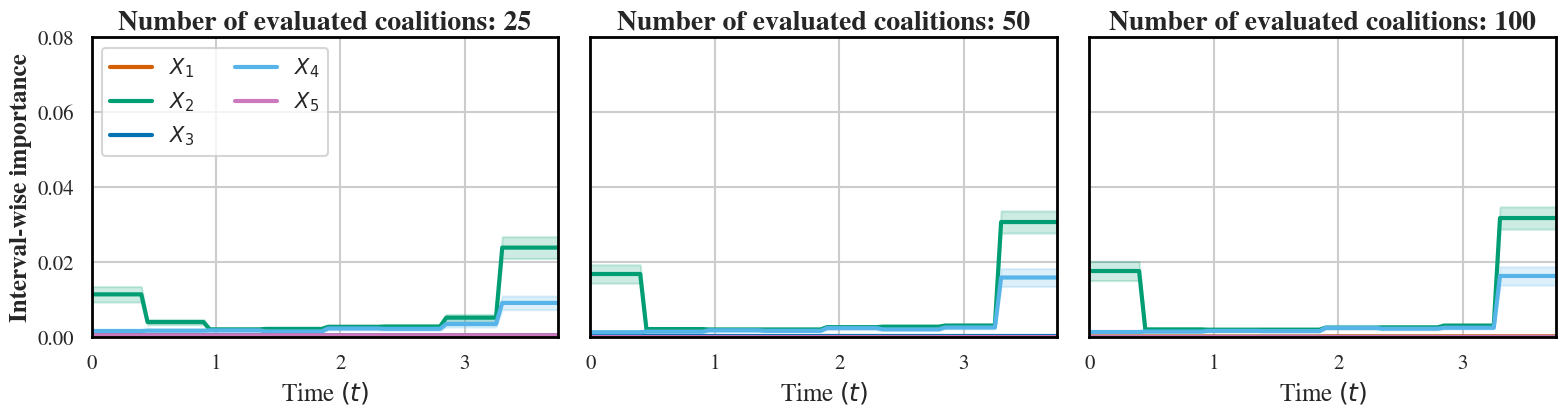

In [15]:
# ============================================================
# WindowSHAP: comparison across coalition budgets
# ============================================================

coalitions = [25, 50, 100]
prediction_idx = 1
prediction_time, horizon_idx = prediction_horizon(prediction_idx)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, n_coalitions in zip(axes, coalitions):

    # ---------- Load and summarize explanations ----------
    results = np.load(
        RESULT_DIR / f"shap_simu_mean_CoxSig_window_{n_coalitions}.npy",
        allow_pickle=True,
    )

    summary = importance_summary(results, prediction_idx - 1)

    # ---------- Temporal importance with 95% CI ----------
    plot_temporal(
        ax,
        summary.temporal_mean,
        summary.temporal_ci,
        horizon_idx=horizon_idx,
    )

    style_axis(
        ax,
        f"Number of evaluated coalitions: {n_coalitions}",
        (0, 0.08),
    )

    ax.set_xlim(sampling_times[0], sampling_times[horizon_idx - 1])
    ax.set_xlabel(r"Time $(t)$")

axes[0].set_ylabel("Interval-wise importance", fontweight="semibold")
axes[0].legend(ncols=2, fontsize=15, loc="upper left")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "shap_simu_mean_score_per_longi_compare_coalition.pdf",
    bbox_inches="tight",
)
plt.show()